# Notebook 03 — Data Quality Audit

**AI Evolution Map · Data Pipeline**

---

## Purpose

Investigate the raw ingested datasets using Pandas to understand their structure,
quality issues, and completeness before any cleaning is applied.

**Rule**: We do not modify raw data here. We only read, inspect, and report.
Every finding is calculated from the actual ingested data, not invented.

## What we check

1. Dataset shapes (rows × columns)
2. Column data types and null counts
3. Missing-value percentages
4. Duplicate record detection
5. Invalid or unexpected date formats
6. URL validity
7. Inconsistent category values
8. Coverage gaps (which years / categories have few records)

In [1]:
import sys
from pathlib import Path

project_root = Path('..').resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RAW_DIR = project_root / 'data' / 'raw'

sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 60)

print('Libraries loaded. Reading raw data from:', RAW_DIR)

Libraries loaded. Reading raw data from: C:\Users\MANAS\Documents\AI-Evolution-Map\data\raw


In [2]:
# Helper: missing value summary
def missing_value_report(df: pd.DataFrame, name: str) -> pd.DataFrame:
    """
    Return a DataFrame summarising missing values per column.
    This is the first diagnostic step for any new dataset.
    """
    total = len(df)
    missing = df.isnull().sum()
    pct = (missing / total * 100).round(1)
    report = pd.DataFrame({
        'column': df.columns,
        'dtype': df.dtypes.values,
        'missing_count': missing.values,
        'missing_pct': pct.values
    }).sort_values('missing_pct', ascending=False)
    report = report[report['missing_count'] > 0]
    print(f'\n=== Missing Values: {name} ({total} rows) ===')
    if report.empty:
        print('No missing values found.')
    return report

## Section 1: OpenAlex Data Audit

In [3]:
from src.ingestion.openalex_client import extract_source_fields

# Load raw file
oa_raw_path = RAW_DIR / 'openalex_ai_works_2018_2023.json'

if not oa_raw_path.exists():
    print('ERROR: OpenAlex raw file not found. Run Notebook 02 first.')
else:
    with open(oa_raw_path, encoding='utf-8') as f:
        oa_raw = json.load(f)

    # Extract fields we care about (read-only — raw data stays unchanged)
    oa_extracted = [extract_source_fields(r) for r in oa_raw]
    df_oa = pd.DataFrame(oa_extracted)

    print(f'OpenAlex: {df_oa.shape[0]} rows × {df_oa.shape[1]} columns')
    print('\nColumn dtypes:')
    print(df_oa.dtypes)
    display(df_oa.head(3))

OpenAlex: 25 rows × 11 columns

Column dtypes:
openalex_id          str
our_source_id        str
title                str
year               int64
doi                  str
cited_by_count     int64
concepts          object
authors           object
venue                str
oa_url               str
work_type            str
dtype: object


,openalex_id,our_source_id,title,year,doi,cited_by_count,concepts,authors,venue,oa_url,work_type
0,https://openalex.org/W4390473182,source-openalex-w4390473182,Optimized multivariate multiscale slope entropy for nonl...,2023,https://doi.org/10.1016/j.chaos.2023.114436,71,"[{'id': 'https://openalex.org/C161584116', 'name': 'Mult...","[Yuxing Li, Bingzhao Tang, Shangbin Jiao, Yuhan Zhou]",Chaos Solitons & Fractals,NaN,article
1,https://openalex.org/W4390467900,source-openalex-w4390467900,Detecting and diagnosing prior and likelihood sensitivit...,2023,https://doi.org/10.1007/s11222-023-10366-5,69,"[{'id': 'https://openalex.org/C21200559', 'name': 'Sensi...","[Noa Kallioinen, Topi Paananen, Paul‐Christian Bürkner, ...",Statistics and Computing,https://link.springer.com/content/pdf/10.1007/s11222-023...,article
2,https://openalex.org/W4390473258,source-openalex-w4390473258,Optimal power distribution control in modular power arch...,2023,https://doi.org/10.1016/j.apenergy.2023.122540,66,"[{'id': 'https://openalex.org/C101468663', 'name': 'Modu...","[Mingda Fei, Zhenyu Zhang, Wenbo Zhao, Peng Zhang, Zhaol...",Applied Energy,NaN,article


In [4]:
if 'df_oa' in dir():
    # Missing value report
    display(missing_value_report(df_oa, 'OpenAlex'))

    # Duplicate ID check
    dup_ids = df_oa[df_oa.duplicated('openalex_id', keep=False)]
    print(f'\nDuplicate openalex_id rows: {len(dup_ids)}')

    # Year distribution
    print('\nPublication year distribution:')
    print(df_oa['year'].value_counts().sort_index())


=== Missing Values: OpenAlex (25 rows) ===


,column,dtype,missing_count,missing_pct
9,oa_url,str,9,36.0



Duplicate openalex_id rows: 0

Publication year distribution:
year
2023    25
Name: count, dtype: int64


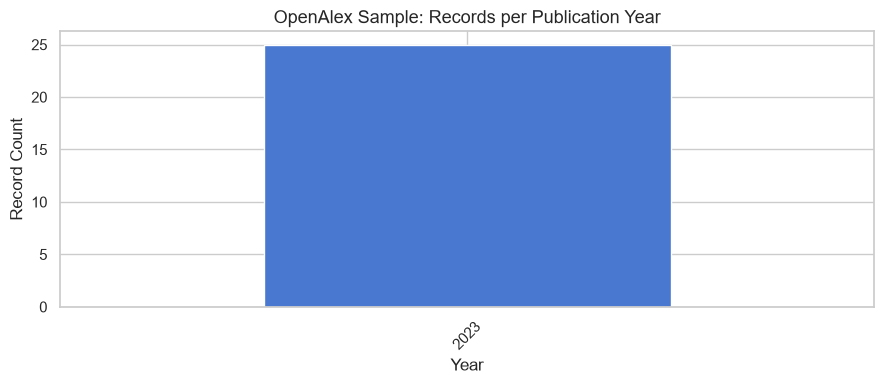

Note: This is a SAMPLE of 100 records — not a complete count of AI publications.


In [5]:
if 'df_oa' in dir():
    # Plot: records per year
    fig, ax = plt.subplots(figsize=(9, 4))
    year_counts = df_oa['year'].value_counts().sort_index()
    year_counts.plot(kind='bar', ax=ax, color=sns.color_palette('muted')[0])
    ax.set_title('OpenAlex Sample: Records per Publication Year', fontsize=13)
    ax.set_xlabel('Year')
    ax.set_ylabel('Record Count')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
    plt.tight_layout()
    plt.savefig('../docs/audit_oa_by_year.png', dpi=100)
    plt.show()
    print('Note: This is a SAMPLE of 100 records — not a complete count of AI publications.')

## Section 2: arXiv Data Audit

In [6]:
arxiv_raw_path = RAW_DIR / 'arxiv_cs_ai_recent_50.json'

if not arxiv_raw_path.exists():
    print('ERROR: arXiv raw file not found. Run Notebook 02 first.')
else:
    with open(arxiv_raw_path, encoding='utf-8') as f:
        arxiv_raw = json.load(f)

    df_arxiv = pd.DataFrame(arxiv_raw)
    print(f'arXiv: {df_arxiv.shape[0]} rows × {df_arxiv.shape[1]} columns')
    display(df_arxiv[['arxiv_id', 'title', 'published', 'primary_category', 'authors']].head(5))

    # Missing values
    display(missing_value_report(df_arxiv, 'arXiv'))

    # Category distribution
    print('\nPrimary category distribution:')
    print(df_arxiv['primary_category'].value_counts())

arXiv: 25 rows × 13 columns


,arxiv_id,title,published,primary_category,authors
0,2610.31667,Direct Pass@$k$ Optimization for Thought Pruning: Balanc...,2026-10-22,cs.AI,"[Mahdi Salmani, Adel Javanmard, Devansh Gupta, Meisam Ra..."
1,2610.31657,Cost-Aware Abstention for LLM-Based IT Ticket Classifica...,2026-10-22,cs.LG,[Sachin Gupta]
2,2610.31656,METTA: Memory-Enhanced Test-Time Adaptation for Meta-Rei...,2026-10-22,cs.LG,"[Ali Najar, Hosein Hasani, Amir Kooshan Fattah, Yasamin ..."
3,2610.31650,EpiSEM-Bench: Evaluating Safety and Evidence Recovery in...,2026-10-22,cs.AI,"[Qijin Zhang, Hanzhen Wang, Yuehan Zhao, Haoyu Dai, Yao ..."
4,2610.31646,Low-Bit N-Gram Embeddings for Language Models,2026-10-22,cs.CL,"[Stephen Chung, Wenyu Du]"



=== Missing Values: arXiv (25 rows) ===


,column,dtype,missing_count,missing_pct
10,journal_ref,object,25,100.0
9,doi,object,25,100.0



Primary category distribution:
primary_category
cs.AI    11
cs.LG     7
cs.CL     4
cs.SE     1
cs.CR     1
cs.CV     1
Name: count, dtype: int64


## Section 3: Hugging Face Hub Audit

In [7]:
from src.ingestion.huggingface_client import extract_model_fields

hf_raw_path = RAW_DIR / 'huggingface_text_generation_top50.json'

if not hf_raw_path.exists():
    print('ERROR: HF Hub raw file not found. Run Notebook 02 first.')
else:
    with open(hf_raw_path, encoding='utf-8') as f:
        hf_raw = json.load(f)

    hf_extracted = [extract_model_fields(r) for r in hf_raw]
    df_hf = pd.DataFrame(hf_extracted)
    print(f'HF Hub: {df_hf.shape[0]} rows × {df_hf.shape[1]} columns')
    display(df_hf[['model_id', 'pipeline_tag', 'downloads', 'likes', 'created_at', 'license']].head(5))

    # Missing values
    display(missing_value_report(df_hf, 'HF Hub'))

    # License distribution
    print('\nLicense distribution:')
    print(df_hf['license'].value_counts(dropna=False))

HF Hub: 25 rows × 14 columns


,model_id,pipeline_tag,downloads,likes,created_at,license
0,Qwen/Qwen3-0.6B,text-generation,25158033,1846,2025-04-27T03:40:08.000Z,None
1,openai-community/gpt2,text-generation,18836643,3891,2022-03-02T23:29:04.000Z,None
2,Qwen/Qwen3-4B,text-generation,11396683,770,2025-04-27T03:41:29.000Z,None
3,Qwen/Qwen3-14B,text-generation,9401416,518,2025-04-27T03:42:45.000Z,None
4,Qwen/Qwen3-Embedding-0.6B,feature-extraction,8126298,1308,2025-06-03T14:25:32.000Z,None



=== Missing Values: HF Hub (25 rows) ===


,column,dtype,missing_count,missing_pct
11,license,object,25,100.0



License distribution:
license
None    25
Name: count, dtype: int64


In [8]:
# ── Audit Summary ─────────────────────────────────────────────────────────────
# We'll write this as a structured dict that Notebook 03 saves
# and docs/data-quality-report.md uses as its basis.

audit_findings = {
    'audit_date': pd.Timestamp.now(tz='UTC').isoformat(),
    'sources': {}
}

for name, df_var in [('openalex', 'df_oa'), ('arxiv', 'df_arxiv'), ('huggingface', 'df_hf')]:
    if df_var in dir():
        df = eval(df_var)  # noqa: eval used intentionally for brevity in notebook
        audit_findings['sources'][name] = {
            'row_count': len(df),
            'column_count': len(df.columns),
            'missing_value_columns': int(df.isnull().any(axis=0).sum()),
            'fully_complete_columns': int((~df.isnull().any(axis=0)).sum()),
        }

import json
audit_path = project_root / 'data' / 'interim' / 'audit_findings.json'
audit_path.parent.mkdir(parents=True, exist_ok=True)
with open(audit_path, 'w') as f:
    json.dump(audit_findings, f, indent=2, default=str)

print(f'Audit findings saved to: {audit_path}')
print(json.dumps(audit_findings, indent=2, default=str))

Audit findings saved to: C:\Users\MANAS\Documents\AI-Evolution-Map\data\interim\audit_findings.json


{
  "audit_date": "2026-10-23T23:37:05.270510+00:00",
  "sources": {
    "openalex": {
      "row_count": 25,
      "column_count": 11,
      "missing_value_columns": 1,
      "fully_complete_columns": 10
    },
    "arxiv": {
      "row_count": 25,
      "column_count": 13,
      "missing_value_columns": 2,
      "fully_complete_columns": 11
    },
    "huggingface": {
      "row_count": 25,
      "column_count": 14,
      "missing_value_columns": 1,
      "fully_complete_columns": 13
    }
  }
}
